# Visualising the Fire Weather Index (FWI) for the European State of the Climate (ESOTC) assessment (solved)

**Author**: Copernicus Climate Change Service (C3S), ECMWF


## About

This notebook is adapted from the C3S training notebook [Visualising the Fire Weather Index (FWI) for the European State of the Climate (ESOTC) assessment](https://ecmwf-projects.github.io/copernicus-training-c3s/visualising-fwi-for-esotc.html), by the Copernicus Climate Change Service (C3S), ECMWF, © 2022. It is used in Module 8, *Advanced use of climate data and C3S tools*, of the [*Understanding Climate Data*](https://climate.copernicus.eu/online-course-understanding-climate-data) online course of the Copernicus Climate Change Service (C3S).

The calculations follow the original. To keep the download short enough for this course, we only download data for Europe and use a 5-year reference period (2016–2020) instead of the 30-year period of the original (1991–2020).

<div class="alert alert-block alert-info">
<b>Note:</b> The data used in this notebook were provided by the <a href="https://effis.jrc.ec.europa.eu">CEMS-EMS European Forest Fire Information System – EFFIS</a> of the European Commission Joint Research Centre and can be accessed via the <a href="https://ewds.climate.copernicus.eu/cdsapp#!/dataset/cems-fire-historical-v1?tab=overview">Climate Data Store</a>. If you use this data, we require that you to acknowledge the source using the citation below:

Copernicus Climate Change Service, Climate Data Store, (2019): Fire danger indices historical data from the Copernicus Emergency Management Service. Copernicus Climate Change Service (C3S) Climate Data Store (CDS). DOI: <a href="https://doi.org/10.24381/cds.0e89c522">10.24381/cds.0e89c522</a> (Accessed on DD-MMM-YYYY)

</div>

## Running this notebook

This is the **solved version** of the notebook: all the code has already been run, so you can read the outputs (figures, tables and printed results) without running anything.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/isaldiviagonzatti/2027-c3s-climate-data-m8/blob/main/visualising-fwi-for-esotc_solved.ipynb)

To run the notebook yourself, open the [original version](https://colab.research.google.com/github/isaldiviagonzatti/2027-c3s-climate-data-m8/blob/main/visualising-fwi-for-esotc.ipynb) in Google Colab. To keep your own changes, use **File > Save a copy in Drive** once the notebook is open in Colab.

## Introduction

Wildfires develop where there is available combustible vegetation and an ignition source, such as from lightning strikes or from human activity. Once ignited, there are several elements that influence fire development. For example, the type and structure of vegetation and its moisture content affect the duration and intensity of a fire event and the topography and wind affect the direction and speed of spread. 

To understand how the flammability of a particular area changes in response to weather conditions, and to assess the potential spread and intensity of a fire, fire danger indices are used, such as the Fire Weather Index (FWI), which express a measure of landscape flammability. Although they do not provide information on actual fires, as they do not consider the ignition, they have been shown to correlate with fire activity expressed in terms of burnt area. Indices such as FWI are calculated from daily temperature, relative humidity, wind speed and precipitation, and take into account the moisture content of potential fuels. Their values also reflect the weather conditions over the preceding days to months.

This notebook demonstrates how to:

- Access, download and open the CEMS FWI data from the EWDS
- Extract the summer months and count the days with high fire danger (FWI > 50)
- Compare 2022 with a reference period (2016–2020)
- Plot maps of the FWI anomaly for Europe and selected sub-regions
- Plot weekly time series of the FWI for the European regions

### Before you start: get access to the data

The FWI data are part of the Copernicus Emergency Management Service (CEMS) and are downloaded from the Copernicus [Early Warning Data Store (EWDS)](https://ewds.climate.copernicus.eu). You need:

1. A free ECMWF account. This is the same account as for the Climate Data Store (CDS). Register or log in at the [Early Warning Data Store (EWDS)](https://ewds.climate.copernicus.eu).
2. To accept the [Terms of use of the CEMS Early Warning Data Store](https://ewds.climate.copernicus.eu/licences/terms-of-use-cems) (log in, open the link and accept). Even if you already use the CDS, you need to accept these separately.
3. To accept the licence of the dataset [Fire danger indices historical data from the Copernicus Emergency Management Service](https://ewds.climate.copernicus.eu/datasets/cems-fire-historical-v1). Open the dataset page, go to the **Download** tab and accept the terms of use at the bottom of the page. You only need to do this once.
4. Your **personal access token**. You can find it on your profile page once you are logged in (see the [API how-to page](https://ewds.climate.copernicus.eu/how-to-api)).

If you cannot get access, or the download takes too long, the notebook also offers a **quick option** that downloads a copy of the same data from the course GitHub repository, without an account (see Section 1).

The notebook will ask you to paste your token when it needs it. The token is not shown on screen and is not saved in the notebook.

---
## Prepare your environment

Before we begin, we must prepare our environment. This includes installing the Application Programming Interface (API) of the data store, and importing the various Python libraries we will need:
- `cdsapi` to download the data
- `xarray` and `dask` to work with large multidimensional arrays
- `cartopy` and `matplotlib` to plot maps

Google Colab already includes most of these packages. Run the cell below to install the missing ones. This may take a minute.

In [1]:
%pip install -q "cdsapi>=0.7.0" cartopy netCDF4

In [2]:
import os
from getpass import getpass

# CDS API
import cdsapi

# working with multidimensional arrays
import xarray as xr
import numpy as np

# libraries for plotting and visualising the data
import cartopy as cart
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.colors as colors

import datetime as dt

## 1. Search and download the data

### Enter your access token

We will request data from the Early Warning Data Store (EWDS) programmatically with the help of the CDS API (the same Python package works for both data stores). To connect, we need two things:

- The `URL` of the EWDS API. This is the same for everyone and you do not need to change it.
- Your personal access token, the `KEY`. The cell below asks you to paste it. The token is not shown on screen and is not saved in the notebook.

In [3]:
EWDS_URL = "https://ewds.climate.copernicus.eu/api"

# Use the token from the EWDS_KEY environment variable if it is set,
# otherwise ask for it
EWDS_KEY = os.environ.get("EWDS_KEY") or getpass("Enter your personal access token: ")

Here we specify a data directory in which we will download our data and all output files that we will generate:

In [4]:
# Only need to be run once
DATADIR = './data_dir'
os.makedirs(DATADIR, exist_ok=True)

### Find the fire danger indices historical data

In this notebook we calculate and plot the difference between number of days when FWI>50 in 2022 and the mean number in the reference period 2016-2020, over Europe. The data can be found in [Fire danger indices historical data from the Copernicus Emergency Management Service](https://ewds.climate.copernicus.eu/cdsapp#!/dataset/cems-fire-historical-v1?tab=form)

<div class="alert alert-block alert-info">
<b>Note:</b> In this demonstrative example we use only 5 years (2016–2020) as the reference period, and we only download data for Europe, to keep the download short. For a representative climatology a period of 30 years is advised, and the latest ESOTC reports use the period 1991–2020. Downloading the six yearly files takes about 20 minutes (each request waits in the queue of the data store, so this can vary). The files are only downloaded once: if you run the cell again, the files that already exist are skipped.
</div>

For this example, we are using the following selection on the download page:
- **Product Type** : 'Reanalysis',
- **Variable** : 'Fire Weather Index',
- **System Version** : '4.1',
- **Dataset Type** : 'Consolidated Dataset',
- **Year** : '2016', '2017', '2018', '2019', '2020' and '2022',
- **Geographical area** : 'Sub-region extraction', North: 75, West: -30, South: 30, East: 45,
- **Day** : '1-31',
- **Grid** : '0.5/0.5',
- **Format** : 'netcdf',

After filling out the download form, select "**Show API request**". This will reveal a block of code, which you can simply copy and paste into a cell of your Jupyter Notebook. One important thing before being able to download the request, is to accept the **Terms of use** in the cell just before the API request. Having double checked your request, and accepted the terms of use, your request should be similar to that shown in the cell below. Please note we have added some additional lines which ensure that we do not repeat the download if we have already downloaded the file and include the option to provide the cdsapi credentials when we start the Client.

In [5]:
# if you're not changing the request, only need to be run once
# Choose the name and location of the download file
download_file = f"{DATADIR}/download_*.nc"

c = cdsapi.Client(url=EWDS_URL, key=EWDS_KEY)

# The CDS request based on your selections for this example:
# reference period 2016-2020, and 2022 as the year of interest
for year in [2016, 2017, 2018, 2019, 2020, 2022]:
    if not os.path.isfile(f'{DATADIR}/download_{year}.nc'):
        c.retrieve(
        'cems-fire-historical-v1',
        {
            'product_type': 'reanalysis',
            'variable': 'fire_weather_index',
            'system_version': '4_1',
            'dataset_type': 'consolidated_dataset',
            'year': year,
            'month': [
                '01', '02', '03',
                '04', '05', '06',
                '07', '08', '09',
                '10', '11', '12',
            ],
            'day': [
                '01', '02', '03',
                '04', '05', '06',
                '07', '08', '09',
                '10', '11', '12',
                '13', '14', '15',
                '16', '17', '18',
                '19', '20', '21',
                '22', '23', '24',
                '25', '26', '27',
                '28', '29', '30',
                '31',
            ],
            'grid': '0.5/0.5',
            'area': [75, -30, 30, 45],  # North, West, South, East: Europe
            'data_format': 'netcdf'
        },
        f'{DATADIR}/download_{year}.nc')

2026-11-21 19:53:54,893 INFO [2026-10-26T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-21 19:53:59,115 WARNING [2026-11-12T00:00:00] On Monday, 16th November 2026, updates to this dataset will cease until further notice. A new mars configuration is required to support this dataset into the future.
Please see [this page](https://confluence.ecmwf.int/spaces/CEMS/pages/738062330/Upgrade+of+the+Global+Wildfire+Mars+structure) for further details.
2026-11-21 19:53:59,116 INFO Request ID is 2b8fad00-8ab2-46b5-b13b-b4f587629cc7
2026-11-21 19:53:59,185 INFO status has been updated to accepted
2026-11-21 19:54:20,398 INFO status has been updated to running
2026-11-21 19:56:52,941 INFO status has been updated to successful
2026-11-21 1

### Quick option: get a copy of the data from GitHub

If the download from the EWDS takes too long or does not work, run the cell below instead. It downloads a copy of exactly the same six files from the GitHub repository of this course, which only takes a few seconds and does not need an account or token. The files were downloaded from the EWDS with the request above and are shared under the same [CC-BY-4.0 licence](https://creativecommons.org/licenses/by/4.0/) (see the citation at the top of this notebook).

Files that already exist in the data folder are skipped, so it does no harm to run both cells.

In [ ]:
import requests

# Copy of the EWDS files in the course GitHub repository
GITHUB_DATA_URL = "https://raw.githubusercontent.com/isaldiviagonzatti/2027-c3s-climate-data-m8/main/fwi_data"

for year in [2016, 2017, 2018, 2019, 2020, 2022]:
    path = f'{DATADIR}/download_{year}.nc'
    if not os.path.isfile(path):
        response = requests.get(f"{GITHUB_DATA_URL}/download_{year}.nc", timeout=300)
        response.raise_for_status()
        with open(path, 'wb') as f:
            f.write(response.content)
        print(f"Downloaded {path}")

## 2: Calculate the ESoTC FWI metric

### Load and inspect the data with xarray

To ensure that we do not run out of memory, we open the data using xarray's in-built dask functionality via the keyword `chunks`. In the example below xarray will only load 365 time steps into memory at any one time.

At this point we also set the longitude dimension to the range -180 to +180, the source data is provided from 0 to 360.

In [6]:
# Open all the yearly files as one dataset:
ds = xr.open_mfdataset(
    download_file, chunks={'valid_time': 365}
)

# make sure the fields has the right longitude record from -180 to 180
ds.coords['longitude'] = (ds.coords['longitude'] + 180) % 360 - 180
ds = ds.sortby(ds.longitude)

# We only have one variable (FWI), so we convert to a dataarray for easier computation:
da = ds.fwinx

### Calculate the anomaly in the number of days with Fire Weather Index > 50

The first step is to extract the period we want to analyse (1st May to 30th September) and count the number of days per year where FWI is greater than our threshold, 50.

In [7]:
# Extract the summer months from the data:
da_summer = da.sel(valid_time=ds.valid_time.dt.month.isin([5,6,7,8,9]))

# Count the number of days where the FWI is greater than our threshold, i.e. 50:
fwi_threshold = 50
fwi_over_50 = da_summer.where(da_summer>fwi_threshold)
nday_fwi_over_50 = fwi_over_50.groupby('valid_time.year').count(dim = 'valid_time')
nday_fwi_over_50

<xarray.DataArray 'fwinx' (year: 6, latitude: 91, longitude: 151)> Size: 660kB
dask.array<stack, shape=(6, 91, 151), dtype=int64, chunksize=(1, 46, 76), chunktype=numpy.ndarray>
Coordinates:
  * year       (year) int64 48B 2016 2017 2018 2019 2020 2022
  * latitude   (latitude) float64 728B 75.0 74.5 74.0 73.5 ... 31.0 30.5 30.0
  * longitude  (longitude) float64 1kB -30.0 -29.5 -29.0 ... 44.0 44.5 45.0
    surface    float64 8B 0.0
Attributes: (12/30)
    GRIB_paramId:                             260540
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      13741
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_name:                                Forest fire weather index (as d...
    GRIB_shortName:                           fwinx
    GRIB_units:                               Numeric
    long_name:                                Forest fire weather index (as d...
    units:                                    Numeric
    standard_name:                            unknown

Then we calculate a climatology for the reference period 2016 to 2020 and use that to calculate the anomaly for 2022

In [8]:
# Select years 2016 to 2020 and calculate the mean for each gridcell
nday_fwi_over_50_clim = nday_fwi_over_50.sel(year=slice(2016,2020)).mean(dim='year')

# Subtract the mean from the data for 2022
nday_fwi_over_50_anomaly_2022 = nday_fwi_over_50.sel(year=2022) - nday_fwi_over_50_clim
nday_fwi_over_50_anomaly_2022

<xarray.DataArray 'fwinx' (latitude: 91, longitude: 151)> Size: 110kB
dask.array<sub, shape=(91, 151), dtype=float64, chunksize=(46, 76), chunktype=numpy.ndarray>
Coordinates:
  * latitude   (latitude) float64 728B 75.0 74.5 74.0 73.5 ... 31.0 30.5 30.0
  * longitude  (longitude) float64 1kB -30.0 -29.5 -29.0 ... 44.0 44.5 45.0
    surface    float64 8B 0.0
    year       int64 8B 2022
Attributes: (12/30)
    GRIB_paramId:                             260540
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      13741
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_name:                                Forest fire weather index (as d...
    GRIB_shortName:                           fwinx
    GRIB_units:                               Numeric
    long_name:                                Forest fire weather index (as d...
    units:                                    Numeric
    standard_name:                            unknown

## 3. Plot the data as maps

First we define a plotting function that we will use throughout this section

In [9]:
# Colour scale options for the normal and masked version of the plotting method
#  They are identical except for the grey region between -1 and +1 in the masked version
COLOURS = {
    "normal": ['#135178', '#0a759f', '#3c8db8', '#51c6d7', '#a6d7db', '#fdeaa5', '#fec34d', '#d15d36', '#ad2124', '#772227'],
    "masked": ['#135178', '#0a759f', '#3c8db8', '#51c6d7', '#a6d7db','grey', '#fdeaa5', '#fec34d', '#d15d36', '#ad2124', '#772227'],
}
BOUNDS = {
    "normal":  [-25, -20, -15, -10, -5, 0, 5, 10, 15, 20, 25],
    "masked": [-25, -20, -15, -10, -5, -1, 1, 5, 10, 15, 20, 25],
}
CBAR_TICKS = {
    "normal": [-25, -15, -5, 5, 15, 25],
    "masked": [-25, -15, -5, -1, 1, 5, 15, 25],
}

def produce_map_plot(
    da,  # Data array to plot
    title = "Anomaly in the number of days when FWI>50",
    cbar_title = "Number of days",
    borders=True, projection = ccrs.Robinson(),
    extent = None, figsize=(10,10),
    style = "normal",
):
    # Create a plotting axis
    plt.figure(figsize=figsize, dpi=100)
    ax = plt.axes(projection=projection)

    # Pick the style options
    colours = COLOURS[style]
    bounds = BOUNDS[style]
    cbar_ticks = CBAR_TICKS[style]
    under_colour = colours[0]
    over_colour = colours[-1]

    # Create the custom colormap from the selected options
    my_cmap = (colors.ListedColormap(colours))
    my_cmap.set_over(over_colour)
    my_cmap.set_under(under_colour)

    # Specify the number of discrete levels to use in the colormap
    norm = colors.BoundaryNorm(bounds, my_cmap.N)

    # Plot data with contours and shading
    img = da.plot.contourf(
        ax=ax, transform=ccrs.PlateCarree(), cmap=my_cmap,
        norm=norm, levels=len(bounds), extend='both',
        add_colorbar=False, add_labels=False
    )

    # Add a colour bar
    if cbar_ticks is None:
        cbar_ticks = bounds[::2]
    cbar = plt.colorbar(img, ax=ax, shrink=0.5, ticks=cbar_ticks)
    cbar.set_label(cbar_title)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(size=0, labelsize=10)

    # Add additional features to the plots
    ax.coastlines() # Add coastlines
    ax.set_frame_on(False) # remove frame
    # Add borders if requested
    if borders:
        ax.add_feature(cart.feature.BORDERS, edgecolor='black', lw=1)
    # Set map extent
    if extent is not None:
        ax.set_extent(extent, ccrs.PlateCarree())
    # cover with white oceans:
    ax.add_feature(cart.feature.OCEAN, color='white', lw=0, zorder=100)

    # Add title
    plt.title(title, fontsize=12, fontweight='bold', y=1.05, color='#742425')
    plt.tight_layout()

    # Option to save, but not used
    #plt.savefig('./fwi_anom_europe_v_nowhite.tiff', format='tiff',facecolor='white')

We then use this function to produce a map of the anomaly for 2022 over Europe. Note that we mask areas where the anomaly is in between -1 and 1 to highlight the regions of interest.

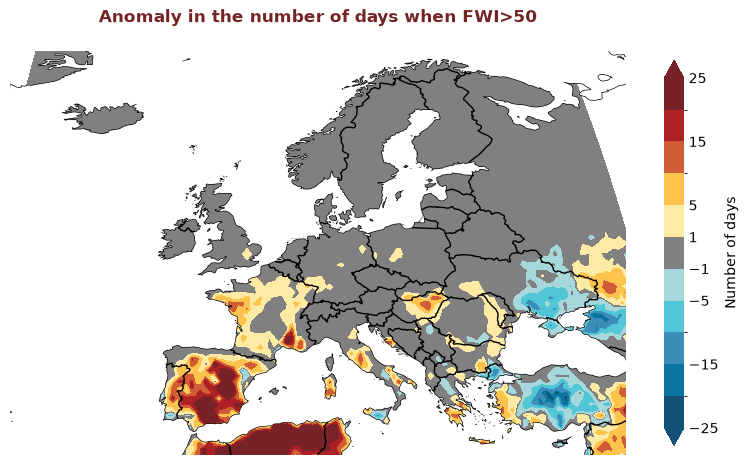

In [10]:
produce_map_plot(
    nday_fwi_over_50_anomaly_2022, borders=True, style="masked",
    extent=[-25, 40, 34, 72], figsize=(8, 8)
)

The figure above displays the 2022 anomaly, with respect to the 2016-2020 reference period, for the number of days where the FWI is considered high, i.e. >50. Red indicates where there were more days with high FWI in 2020 than the reference period, and blue indicates that there were fewer days with high FWI.

### Produce maps for each of the ESOTC Regions

**ESOTC Regions**

Europe: 25°W–40°E, 34°–72°N <br>
Southwestern Europe: 25°W–15°E, 34°–45°N <br>
Northwestern Europe: 25°W–15°E, 45°–72°N <br>
Southeastern Europe: 15°–40°E, 34°–45°N <br>
Northeastern Europe: 15°–40°E, 45°–72°N <br>
Central Europe: 2°–24°E, 45°–55°N

In [11]:
esotc_regions = {
    'Europe':{'extent': [-25,40,34,72], 'limits':[0,20]},
    'Southwestern Europe':{'extent': [-25,15,34,50], 'limits':[0,45]},
    'Northwestern Europe':{'extent': [-25,15,45,72], 'limits':[0,20]},
    'Southeastern Europe':{'extent': [15,40,34,45], 'limits':[0,45]},
    'Northeastern Europe':{'extent': [15,40,45,72], 'limits':[0,20]},
}

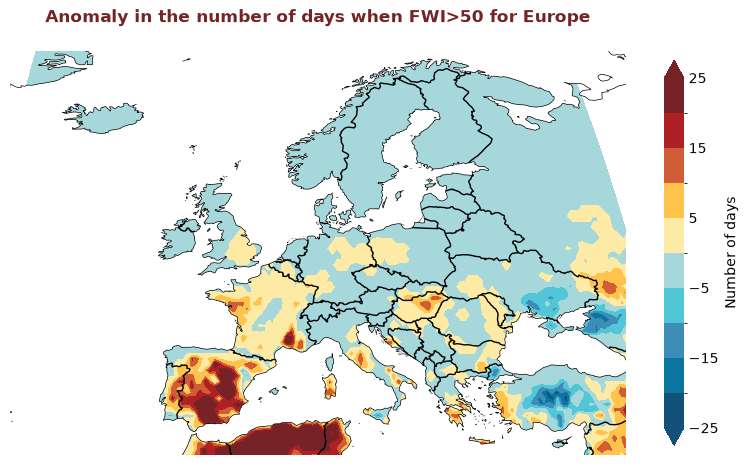

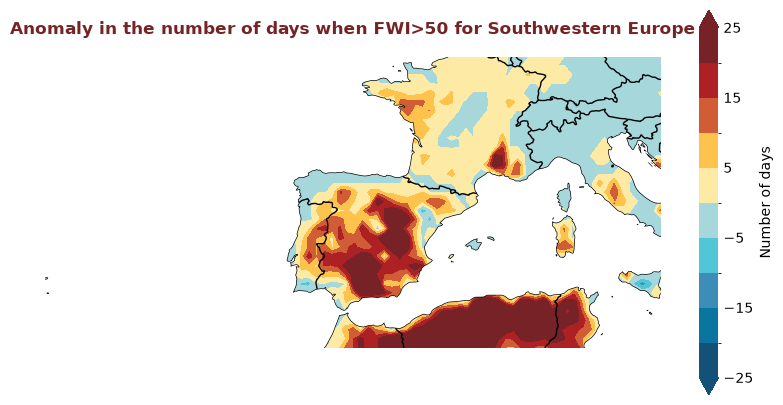

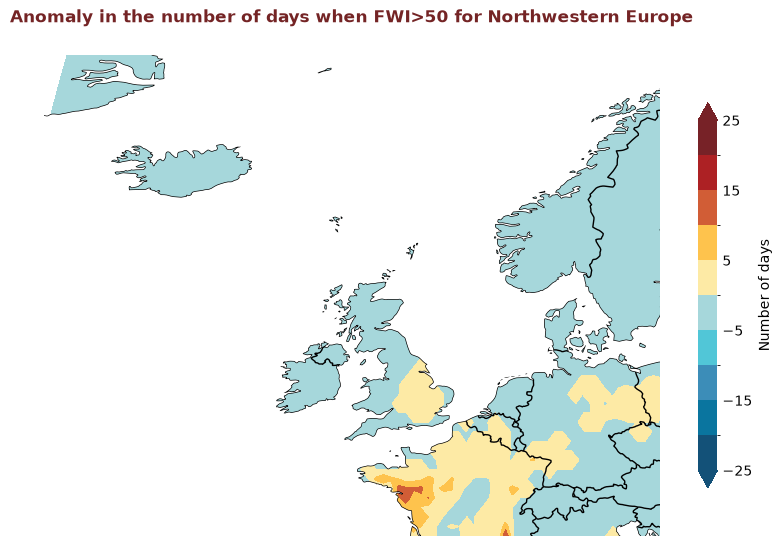

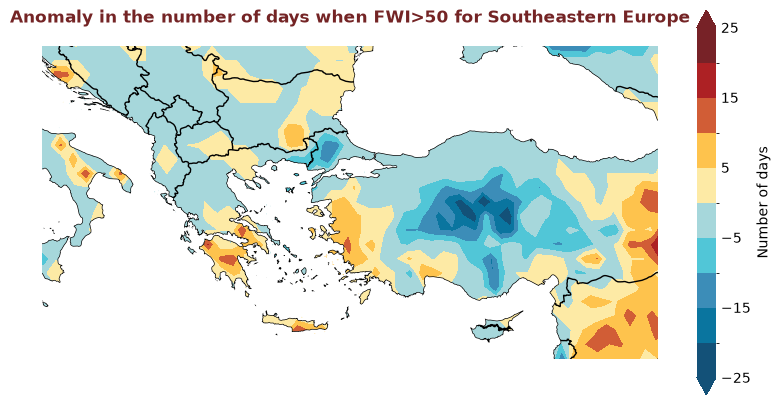

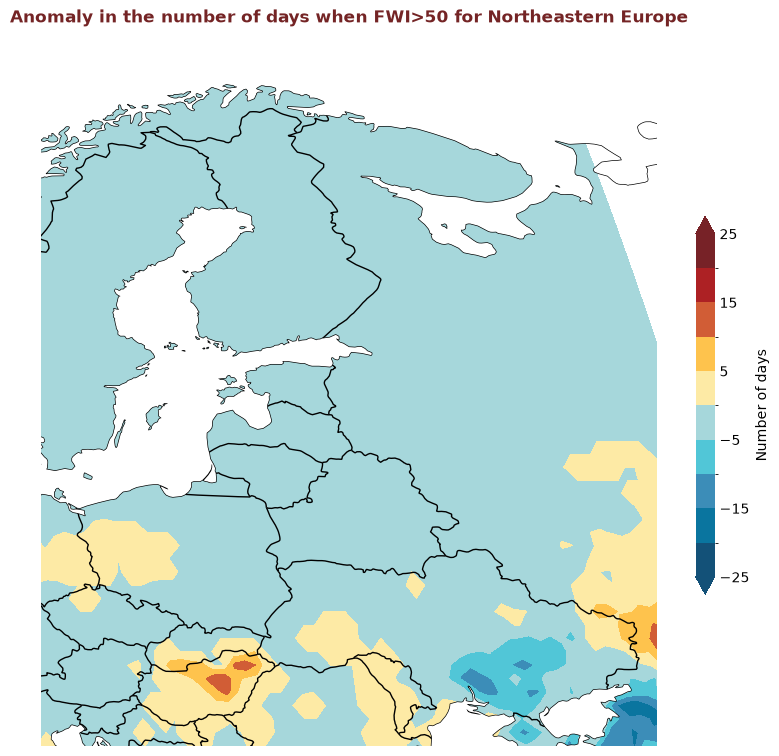

In [12]:
# Take a subset of data to improve plotting speed
europe_data = nday_fwi_over_50_anomaly_2022.sel(
    latitude=slice(80, 25), longitude=slice(-30,80)
)
for region, config in esotc_regions.items():
    extent = config.get('extent')
    # figsize = config.get('figsize', (8,8))
    produce_map_plot(
        europe_data,
        title = "Anomaly in the number of days when FWI>50 for " + region,
        extent = extent, figsize=(8,8)
    )

## 4. Plot weekly time series: 2022 compared with the reference period

For each region, we average the FWI over the region and calculate weekly means. We then compare the weekly FWI in 2022 with the mean, the 10th–90th percentile range and the minimum–maximum range of the 2016–2020 reference period.

Europe
Southwestern Europe
Northwestern Europe
Southeastern Europe
Northeastern Europe


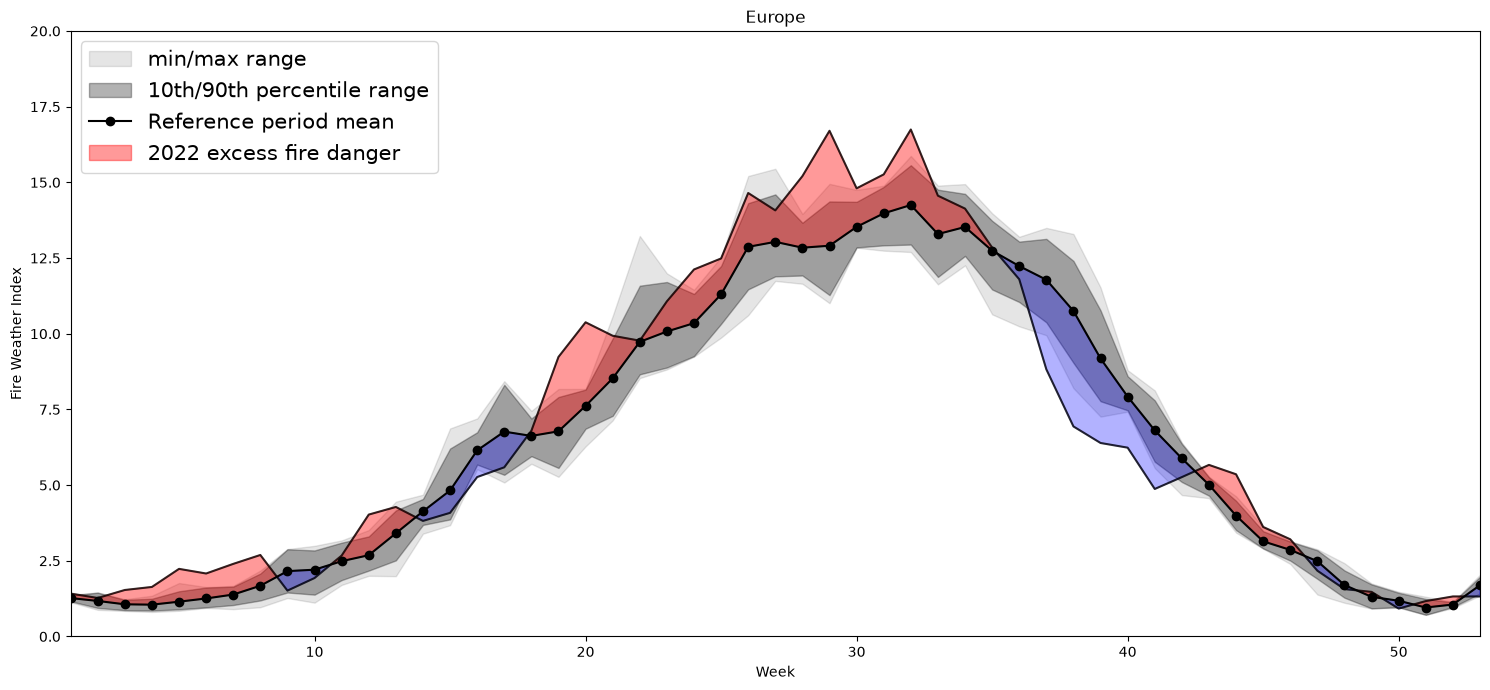

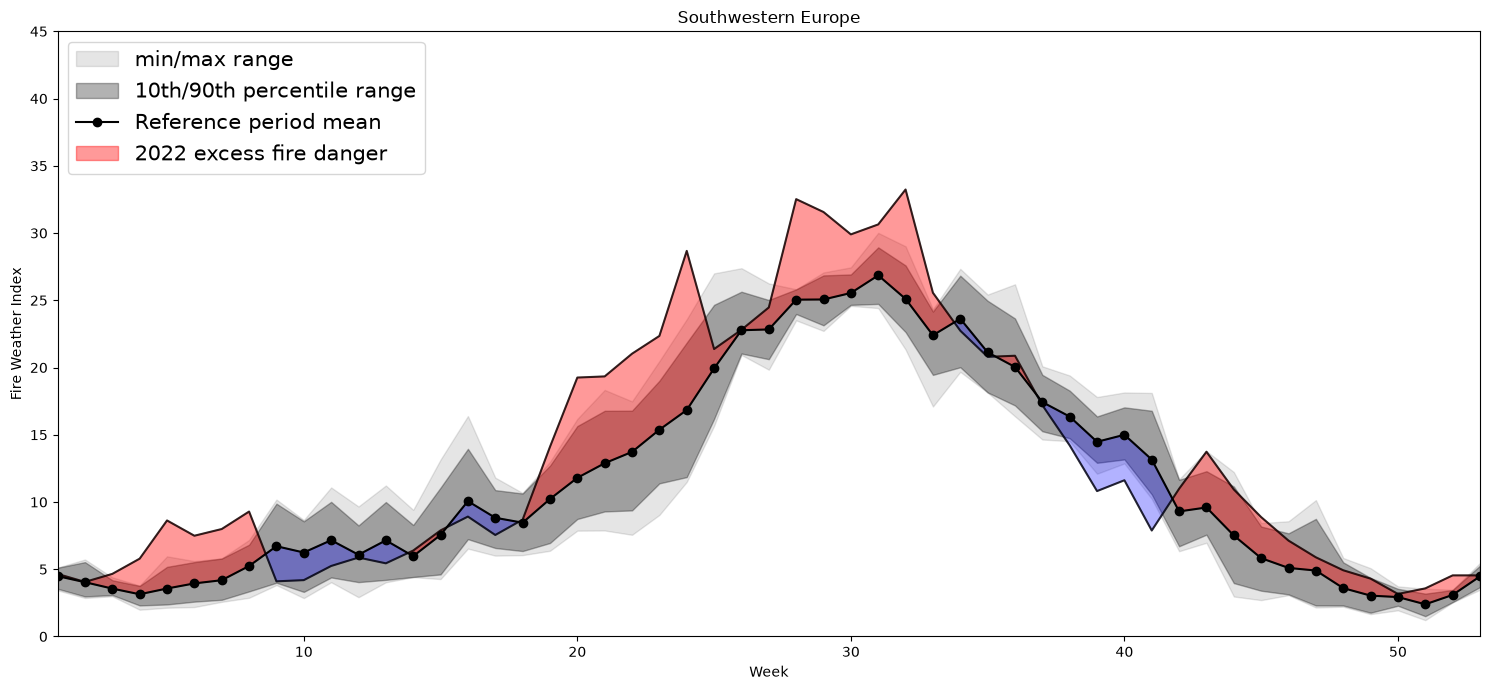

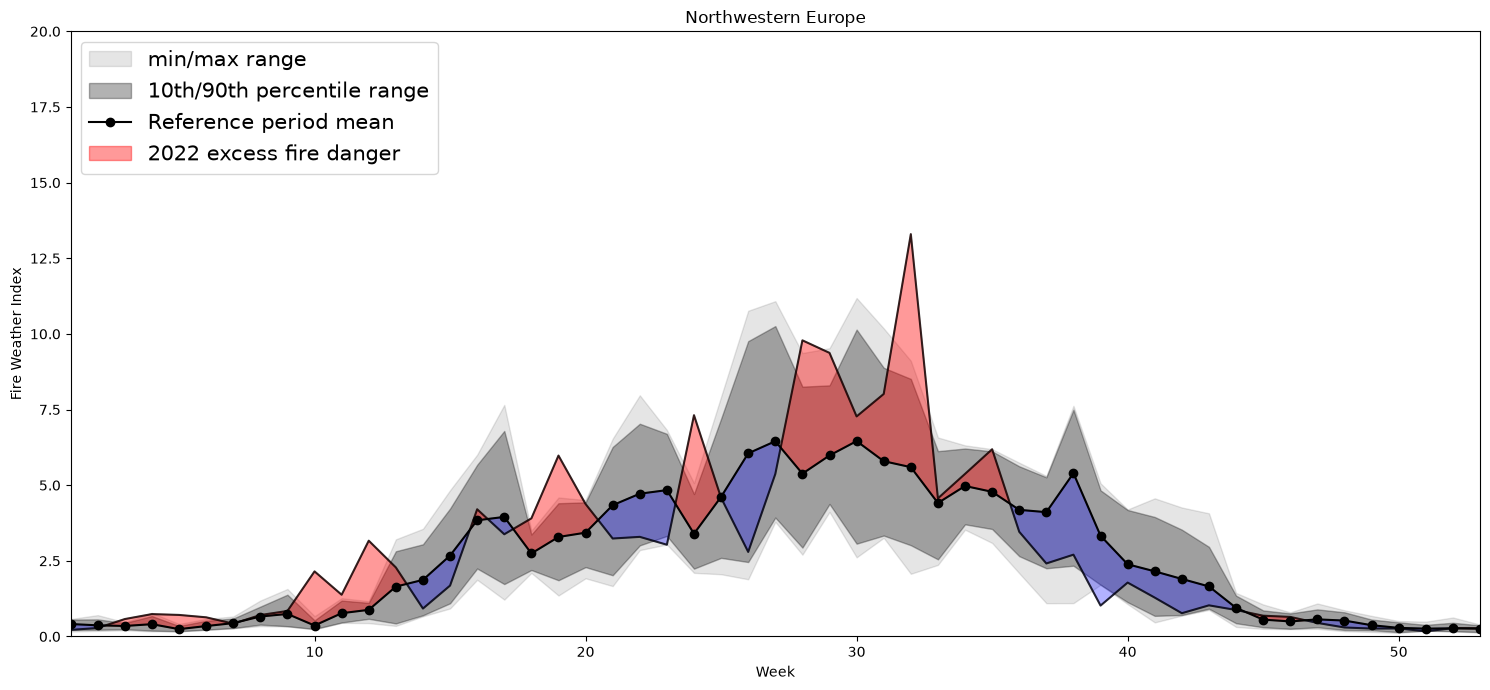

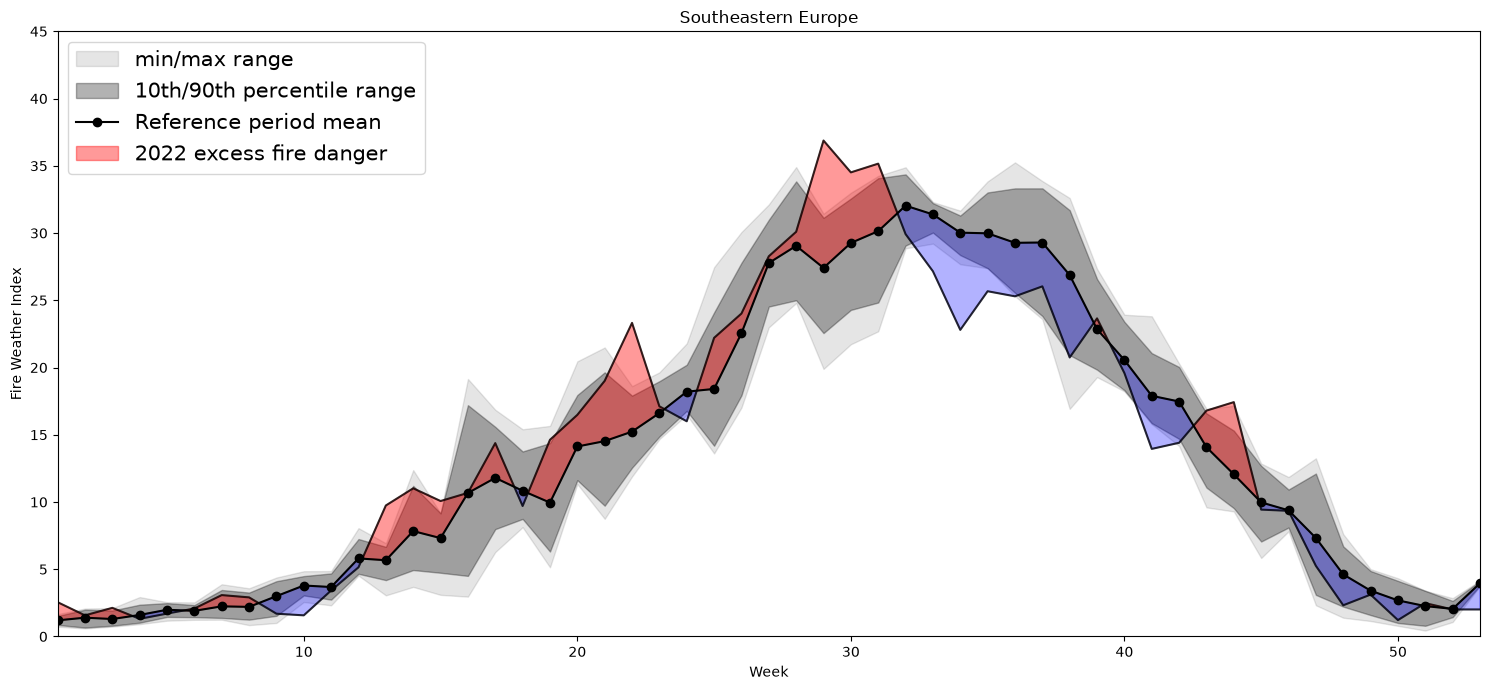

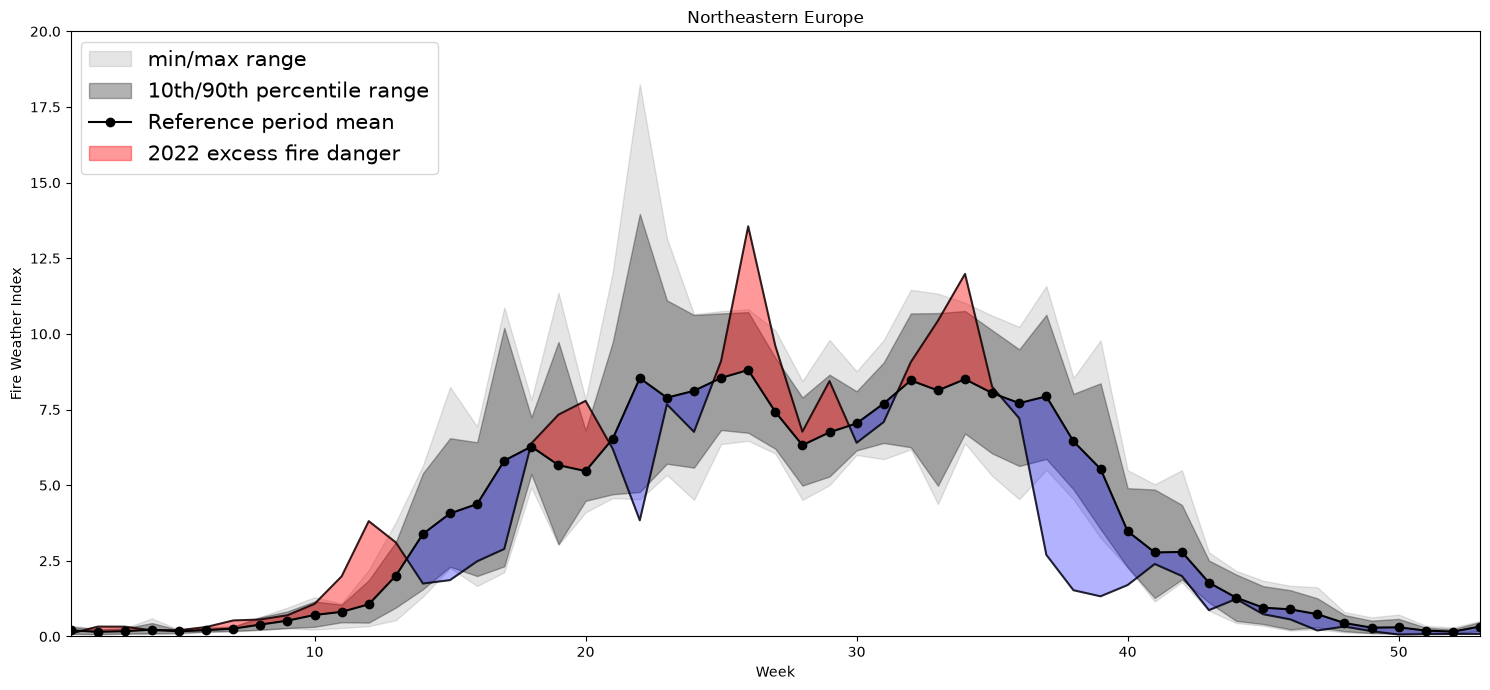

In [13]:
for region, config in esotc_regions.items():
    extent = config.get('extent')
    limits = config.get('limits')
    print(region)
    lon1=extent[0]
    lon2=extent[1]
    lat2=extent[2]
    lat1=extent[3]
    cymin=limits[0]
    cymax=limits[1]
    small = ds.sel(latitude=slice(lat1,lat2), longitude=slice(lon1,lon2))
# Clima 
    clim= small.sel(valid_time=slice('2016-01-01','2020-12-31')).mean(dim=['longitude','latitude'])
    weekly_clim= clim.resample(valid_time='W').mean(dim='valid_time')  
    weekly_clim=weekly_clim.chunk({'valid_time':-1})
    w_clim_mean=weekly_clim.groupby(weekly_clim['valid_time'].dt.isocalendar().week).mean()#.load()
    w_clim_max=weekly_clim.groupby(weekly_clim['valid_time'].dt.isocalendar().week).max()#.load()
    w_clim_min=weekly_clim.groupby(weekly_clim['valid_time'].dt.isocalendar().week).min()#.load()
    w_clim_q10=weekly_clim.groupby(weekly_clim['valid_time'].dt.isocalendar().week).quantile(0.1)#.load()
    w_clim_q90=weekly_clim.groupby(weekly_clim['valid_time'].dt.isocalendar().week).quantile(0.9)#.load()
# this year 
    ty= small.sel(valid_time=slice('2022-01-01','2022-12-31')).mean(dim=['longitude','latitude'])
    weekly_ty= ty.resample(valid_time='W').mean(dim='valid_time')  
    weekly_ty=weekly_ty.chunk({'valid_time':-1})
    w_ty_mean=weekly_ty.groupby(weekly_ty['valid_time'].dt.isocalendar().week).mean()#.load()
# variables for plotting 
    x=w_clim_max['week'].values
    xdate = "2022-W26"
    r = dt.datetime.strptime(xdate + '-1', "%Y-W%W-%w")
    ymean=w_clim_mean.fwinx.values
    ymin=w_clim_min.fwinx.values
    ymax=w_clim_max.fwinx.values
    y10=w_clim_q10.fwinx.values
    y90=w_clim_q90.fwinx.values
    tymean=w_ty_mean.fwinx.values
# this only needed if odd number of weeks 
    tymean=np.append(tymean,tymean[51])
    fig, ax = plt.subplots(1, figsize=(15, 7),dpi=100)
    ax.fill_between(x, ymax, ymin, 
                    color="k", 
                    alpha=0.1, 
                    label='min/max range')
    ax.fill_between(x, y10, y90, 
                    color="k",
                    alpha=0.3, 
                    label='10th/90th percentile range')
    ax.plot(x, ymean, 'o-', 
            color="k", 
            label="Reference period mean")

    ax.fill_between(x, ymean,tymean,
    color="r",
    alpha=0.4,
    where= tymean>= ymean,
    interpolate=True, 
    label="2022 excess fire danger")
 
    ax.fill_between(x, ymean,tymean,
    color="b",
    alpha=0.3,
    where= tymean <= ymean,
    interpolate=True)

    ax.plot(x, tymean, '-', color='black',alpha=0.8)
    ax.legend(loc='upper left',fontsize=15)
    plt.ylim(ymax=cymax,ymin=cymin)  # this line
    plt.xlim(xmax=53,xmin=1)
    plt.title(region)
    ax.set_xlabel('Week')
    ax.set_ylabel('Fire Weather Index')
    plt.tight_layout()
    # plt.savefig(f'{region}_weeklyTS.tiff', format='tiff',facecolor='white')
    
    